### File phân tích data, bao gồm:
- Số lượng doanh nghiệp.
- Số lượng file với từng doanh nghiệp.
- Số câu hỏi, câu trả lời không có câu trả lời, câu hỏi tương ứng.
- Phân bố các kiểu output.
- Số câu hỏi với từng doanh nghiệp


### Cell 1 — Import thư viện và cấu hình đường dẫn

In [1]:
from pathlib import Path
import json
import re
import unicodedata
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Hiển thị dữ liệu
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 150)
pd.set_option("display.width", 160)

# Đường dẫn dataset
BASE_DIR = Path("train data")

DATA_DIR = BASE_DIR / "data"
QUESTION_FILE = BASE_DIR / "questions.jsonl"
ANSWER_FILE = BASE_DIR / "answers.jsonl"

RULEBOOK_FILE = BASE_DIR / "rulebook.md"
CALENDAR_FILE = BASE_DIR / "calendar.csv"

# Kiểm tra đường dẫn
paths = {
    "Data directory": DATA_DIR,
    "Questions": QUESTION_FILE,
    "Answers": ANSWER_FILE,
    "Rulebook": RULEBOOK_FILE,
    "Calendar": CALENDAR_FILE
}

for name, path in paths.items():
    print(f"{name:20}: {'FOUND' if path.exists() else 'NOT FOUND'}")

assert DATA_DIR.exists(), "Không tìm thấy thư mục data/"
assert QUESTION_FILE.exists(), "Không tìm thấy questions.jsonl"
assert ANSWER_FILE.exists(), "Không tìm thấy answers.jsonl"

Data directory      : FOUND
Questions           : FOUND
Answers             : FOUND
Rulebook            : FOUND
Calendar            : FOUND


### Cell 2 — Đọc dữ liệu JSONL

In [2]:
def load_jsonl(file_path):
    """
    Đọc file JSONL thành DataFrame.

    Trả về:
        df: DataFrame chứa các bản ghi hợp lệ.
        errors: DataFrame chứa những dòng không đọc được.
    """

    records = []
    errors = []

    with open(file_path, "r", encoding="utf-8-sig") as f:

        for line_no, line in enumerate(f, start=1):

            line = line.strip()

            if not line:
                continue

            try:
                record = json.loads(line)

                if isinstance(record, dict):
                    records.append(record)
                else:
                    errors.append({
                        "line": line_no,
                        "content": line,
                        "error": "JSON record is not an object"
                    })

            except json.JSONDecodeError as e:
                errors.append({
                    "line": line_no,
                    "content": line,
                    "error": str(e)
                })

    df = pd.DataFrame(records)
    error_df = pd.DataFrame(
        errors,
        columns=["line", "content", "error"]
    )

    return df, error_df


# Load dataset
df_questions, question_errors = load_jsonl(QUESTION_FILE)
df_answers, answer_errors = load_jsonl(ANSWER_FILE)


print("========== DATA LOADING ==========")

print("Total question records:", len(df_questions))
print("Total answer records:", len(df_answers))

print("Invalid question lines:", len(question_errors))
print("Invalid answer lines:", len(answer_errors))

========== DATA LOADING ==========
Total question records: 3000
Total answer records: 3000
Invalid question lines: 0
Invalid answer lines: 0


### Cell 3 — Kiểm tra cấu trúc dữ liệu
Cell này giúp xác nhận dữ liệu thực tế có đúng như kỳ vọng không.


In [3]:
def inspect_dataframe(df, name):

    print(f"\n{'=' * 60}")
    print(name.upper())
    print(f"{'=' * 60}")

    print("Shape:", df.shape)

    print("\nColumns:")
    for col in df.columns:
        print(f"- {col}")

    print("\nMissing values:")
    display(
        df.isnull().sum()
        .rename("missing_count")
        .to_frame()
    )

    print("\nFirst 5 records:")
    display(df.head())


inspect_dataframe(df_questions, "Questions")
inspect_dataframe(df_answers, "Answers")


QUESTIONS
Shape: (3000, 4)

Columns:
- id
- business_id
- question
- as_of_date

Missing values:


,missing_count
id,0
business_id,0
question,0
as_of_date,0



First 5 records:


,id,business_id,question,as_of_date
0,q_001883280e83,biz_128,tháng này tổng giá trị các phiếu nhập hàng là bao nhiu,2026-09-07
1,q_00195e1e4049,biz_124,Thuốc có hoạt chất Natri clorid tháng này bán được tổng cộng bao nhiêu tiền?,2026-05-25
2,q_002d03ebbded,biz_120,Tổng doanh thu trong ngày hôm nay là bao nhiêu?,2025-04-30
3,q_00558c1410ef,biz_105,tỉ lệ huỷ đơn tháng 6/2025 là nhiêu %,2026-06-24
4,q_006c26c65d50,biz_112,thang 7/2026 co bao nhiu don co dthu tu 55.000 dong tro len,2026-07-31



ANSWERS
Shape: (3000, 4)

Columns:
- id
- type
- answer
- alias

Missing values:


,missing_count
id,0
type,0
answer,70
alias,0



First 5 records:


,id,type,answer,alias
0,q_001883280e83,number,89526400,[]
1,q_00195e1e4049,number,2954200,[]
2,q_002d03ebbded,number,10309400,[]
3,q_00558c1410ef,percent,2.08,[]
4,q_006c26c65d50,number,2345,[]


In [4]:
required_question_columns = {
    "id",
    "business_id",
    "question",
    "as_of_date"
}

required_answer_columns = {
    "id",
    "type",
    "answer"
}

missing_question_columns = (
    required_question_columns - set(df_questions.columns)
)

missing_answer_columns = (
    required_answer_columns - set(df_answers.columns)
)

print("Missing columns in questions:", missing_question_columns)
print("Missing columns in answers:", missing_answer_columns)

Missing columns in questions: set()
Missing columns in answers: set()


#### => Không có dữ liệu bị thiếu

### Cell 4 — Thống kê số lượng doanh nghiệp và file
Với mỗi doanh nghiệp, ta sẽ thống kê:
- Tổng số file.
- Số file CSV.
- Số file XLSX.
- Số file Markdown.
- Số file có định dạng khác.

In [5]:
# Lấy danh sách thư mục doanh nghiệp
biz_dirs = sorted([
    path for path in DATA_DIR.iterdir()
    if path.is_dir() and path.name.lower().startswith("biz_")
])

print("Total businesses:", len(biz_dirs))


def count_business_files(folder):

    files = [
        path for path in folder.rglob("*")
        if path.is_file()
        and not path.name.startswith(".")
    ]

    extension_counts = Counter(
        path.suffix.lower()
        for path in files
    )

    csv_count = extension_counts[".csv"]
    xlsx_count = extension_counts[".xlsx"]
    md_count = extension_counts[".md"]

    total_count = len(files)

    return {
        "business_id": folder.name,
        "total_files": total_count,
        "csv_files": csv_count,
        "xlsx_files": xlsx_count,
        "md_files": md_count,
        "other_files": total_count - csv_count - xlsx_count - md_count
    }


business_stats = [
    count_business_files(folder)
    for folder in biz_dirs
]

df_business = pd.DataFrame(
    business_stats,
    columns=[
        "business_id",
        "total_files",
        "csv_files",
        "xlsx_files",
        "md_files",
        "other_files"
    ]
)

df_business = df_business.sort_values(
    "business_id"
).reset_index(drop=True)

display(df_business)

Total businesses: 30


,business_id,total_files,csv_files,xlsx_files,md_files,other_files
0,biz_101,2,1,0,1,0
1,biz_102,3,0,2,1,0
2,biz_103,3,0,2,1,0
3,biz_104,3,0,2,1,0
4,biz_105,7,0,6,1,0
5,biz_106,11,0,10,1,0
6,biz_107,2,0,1,1,0
7,biz_108,8,0,7,1,0
8,biz_109,3,0,2,1,0
9,biz_110,2,1,0,1,0


#### Thống kê tổng quan:

In [6]:
print("========== BUSINESS STATISTICS ==========")

print("Number of businesses:", len(df_business))

print("Total files:", df_business["total_files"].sum())

print("CSV files:", df_business["csv_files"].sum())
print("XLSX files:", df_business["xlsx_files"].sum())
print("Markdown files:", df_business["md_files"].sum())
print("Other files:", df_business["other_files"].sum())

print(
    "Average files per business:",
    round(df_business["total_files"].mean(), 2)
)

print(
    "Maximum files per business:",
    df_business["total_files"].max()
)

print(
    "Minimum files per business:",
    df_business["total_files"].min()
)

========== BUSINESS STATISTICS ==========
Number of businesses: 30
Total files: 158
CSV files: 20
XLSX files: 107
Markdown files: 30
Other files: 1
Average files per business: 5.27
Maximum files per business: 14
Minimum files per business: 2


#### => chỉ mỗi biz_123 có 1 file .sqlite, còn lại chỉ có .csv hoặc .xlsx

#### Trực quan hóa:

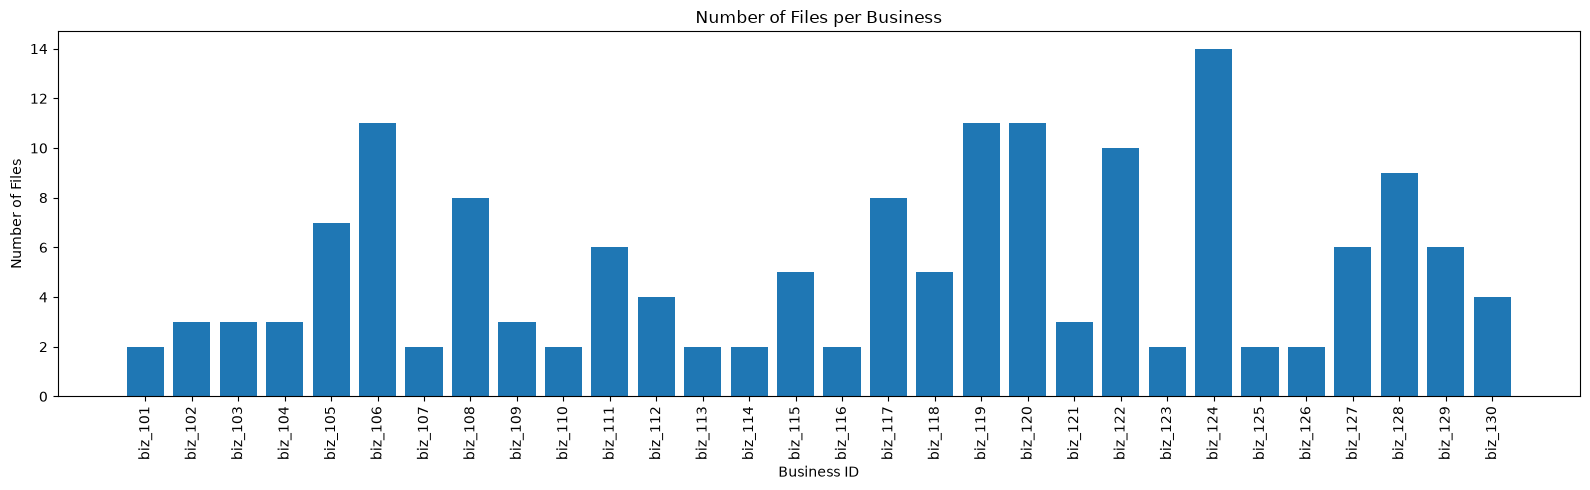

In [7]:
plt.figure(figsize=(16, 5))

plt.bar(
    df_business["business_id"],
    df_business["total_files"]
)

plt.title("Number of Files per Business")
plt.xlabel("Business ID")
plt.ylabel("Number of Files")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Cell 5 — Thống kê câu hỏi và kiểm tra liên kết Question–Answer
Phần này sẽ kiểm tra:
- Tổng số câu hỏi.
- Tổng số answer.
- Số ID câu hỏi bị trùng.
- Số ID answer bị trùng.
- Câu hỏi không có answer tương ứng.
- Answer không có câu hỏi tương ứng.
- Doanh nghiệp có câu hỏi nhưng không có thư mục dữ liệu.

Thống kê số lượng:

In [8]:
# Chuẩn hóa ID
df_questions["id"] = df_questions["id"].astype("string").str.strip()
df_answers["id"] = df_answers["id"].astype("string").str.strip()

df_questions["business_id"] = (
    df_questions["business_id"].astype("string").str.strip()
)

# Thống kê số lượng
print("========== QUESTION / ANSWER STATISTICS ==========")

print("Total questions:", len(df_questions))
print("Unique question IDs:", df_questions["id"].nunique())

print("Total answers:", len(df_answers))
print("Unique answer IDs:", df_answers["id"].nunique())

print(
    "Duplicate question IDs:",
    df_questions["id"].duplicated().sum()
)

print(
    "Duplicate answer IDs:",
    df_answers["id"].duplicated().sum()
)

========== QUESTION / ANSWER STATISTICS ==========
Total questions: 3000
Unique question IDs: 3000
Total answers: 3000
Unique answer IDs: 3000
Duplicate question IDs: 0
Duplicate answer IDs: 0


Kiểm tra các bản ghi không có dữ liệu đối ứng:

In [10]:
question_ids = set(df_questions["id"].dropna())
answer_ids = set(df_answers["id"].dropna())

questions_without_answers = question_ids - answer_ids
answers_without_questions = answer_ids - question_ids

print("Questions without answers:", len(questions_without_answers))
print("Answers without questions:", len(answers_without_questions))

Questions without answers: 0
Answers without questions: 0


Kiểm tra doanh nghiệp:

In [11]:
folder_business_ids = set(df_business["business_id"])

question_business_ids = set(
    df_questions["business_id"].dropna()
)

businesses_without_folder = (
    question_business_ids - folder_business_ids
)

businesses_without_question = (
    folder_business_ids - question_business_ids
)

print("Businesses in questions:", len(question_business_ids))
print("Businesses with data folders:", len(folder_business_ids))

print("Businesses without data folder:", len(businesses_without_folder))
print("Businesses without questions:", len(businesses_without_question))

if businesses_without_folder:
    print("\nBusiness IDs without folder:")
    print(sorted(businesses_without_folder))

Businesses in questions: 30
Businesses with data folders: 30
Businesses without data folder: 0
Businesses without questions: 0


Tạo bảng Question–Answer để sử dụng ở những cell tiếp theo:

In [12]:
# Loại bỏ ID bị null trước khi ghép
q_for_join = df_questions[
    df_questions["id"].notna()
].drop_duplicates("id", keep="first")

a_for_join = df_answers[
    df_answers["id"].notna()
].drop_duplicates("id", keep="first")

df_qa = q_for_join.merge(
    a_for_join,
    on="id",
    how="left",
    suffixes=("_question", "_answer"),
    indicator=True
)

print("Question-Answer merged shape:", df_qa.shape)

print("\nMerge status:")
display(
    df_qa["_merge"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="count")
)

Question-Answer merged shape: (3000, 8)

Merge status:


,status,count
0,both,3000
1,left_only,0
2,right_only,0


### Cell 6 — Phân bố các kiểu output

In [13]:
# Chuẩn hóa trường type
df_answers["output_type"] = (
    df_answers["type"]
    .fillna("unknown")
    .astype(str)
    .str.strip()
    .str.lower()
)

df_output_types = (
    df_answers["output_type"]
    .value_counts()
    .rename_axis("output_type")
    .reset_index(name="count")
)

df_output_types["percentage"] = (
    df_output_types["count"]
    / max(len(df_answers), 1)
    * 100
)

print("========== OUTPUT TYPE DISTRIBUTION ==========")

display(df_output_types)

========== OUTPUT TYPE DISTRIBUTION ==========


,output_type,count,percentage
0,number,1884,62.800000
1,percent,578,19.266667
2,list,193,6.433333
3,date,145,4.833333
4,string,88,2.933333
5,unanswerable,70,2.333333
6,boolean,23,0.766667
7,table,19,0.633333


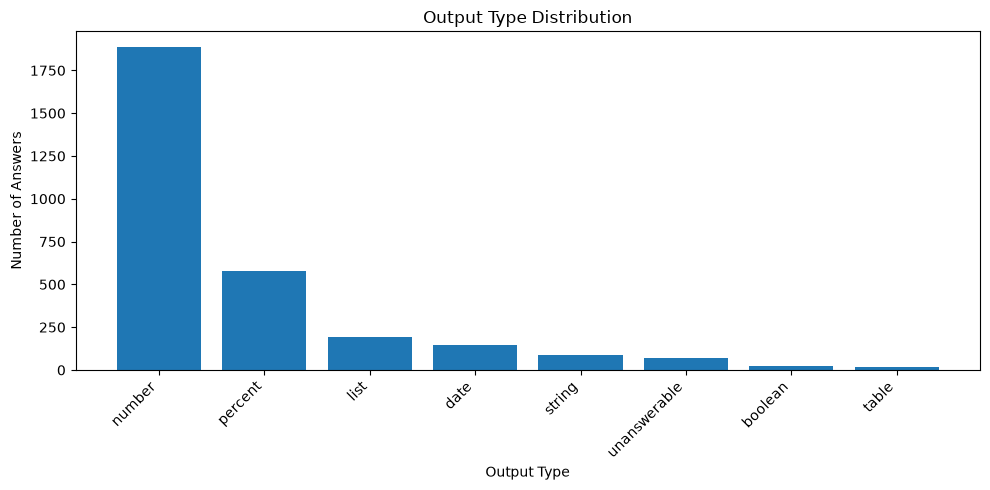

In [14]:
plt.figure(figsize=(10, 5))

plt.bar(
    df_output_types["output_type"],
    df_output_types["count"]
)

plt.title("Output Type Distribution")
plt.xlabel("Output Type")
plt.ylabel("Number of Answers")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### => kiểu trả lời number chiếm phần lớn

#### Kiểm tra 1 số answer thuộc từng loại output

In [15]:
for output_type in sorted(df_answers["output_type"].unique()):

    samples = df_answers.loc[
        df_answers["output_type"] == output_type,
        ["id", "answer", "alias"]
    ].head(5)

    print(f"\n{'=' * 70}")
    print(f"OUTPUT TYPE: {output_type}")
    print(f"{'=' * 70}")

    display(samples)


OUTPUT TYPE: boolean


,id,answer,alias
194,q_0fc33ac2add7,False,[]
642,q_3614b8c3f2b9,False,[]
1086,q_5b66ecfa2ba0,True,[]
1308,q_70d78d0a36ff,True,[]
1437,q_7c42bbc16fde,True,[]



OUTPUT TYPE: date


,id,answer,alias
52,q_046b75d6192e,2025-02-15,[]
56,q_0496b83ca7c4,2026-07-29,[]
58,q_04ad09f4f1fc,2025-03-01,[]
83,q_065aa2aac90c,2026-02-05,[]
93,q_0711d68fb12f,2025-12,[]



OUTPUT TYPE: list


,id,answer,alias
16,q_0183529f9d61,"[287435200, 346554700, 309693800]",[]
18,q_019ec94d9799,"[Cà phê sữa (M), Trà đào cam sả (M), Cà phê đen (M)]","[[SP0003], [SP0017], [SP0001]]"
33,q_02a70ea566f1,"[Cà phê sữa (M), Trà đào cam sả (M), Cà phê đen (M)]","[[SP0003], [SP0017], [SP0001]]"
44,q_040c9dd7f4de,"[Xi măng Hà Tiên PCB40 bao 50kg, Gạch ống 8x8x18 Tuynel, Xi măng INSEE Power-S bao 50kg, Băng keo điện Nano 20 yard, Ống PVC Bình Minh D32 cây 4m]","[[SP0001], [SP0009], [SP0002], [SP0033], [SP0027, Ong PVC Binh Minh D32 cay 4m]]"
55,q_0483a8398dfe,"[173866200, 156289700, 158205600]",[]


... (6 outputs left out)


OUTPUT TYPE: table


,id,answer,alias
132,q_0a76d3680594,"{'columns': ['khach_hang', 'so_tien_no'], 'rows': [['Đỗ Đức An', 404500], ['Dương Tâm Bích', 158600], ['Phùng Hồng Nam', 126000], ['Bạch Dương Phú...","[[KH0124], [KH0233], [KH0137], [KH0187], [KH0110]]"
187,q_0f6f50127e77,"{'columns': ['khach_hang', 'so_tien_no'], 'rows': [['Lâm Bảo Ngọc', 632000], ['Nghiêm Duy Linh', 620000], ['Lương Huy Quang', 360500]]}","[[KH0027], [KH0097], [KH0112]]"
255,q_153f4e995558,"{'columns': ['khach_hang', 'so_tien_no'], 'rows': [['Mai Trang Dũng', 174667], ['Ngô Thảo Châu', 149500], ['Lưu Hà An', 90000]]}","[[KH0190], [KH0082], [KH0056, Luu Ha An]]"
307,q_1a11488ed8c6,"{'columns': ['khach_hang', 'so_tien_no'], 'rows': [['Phạm Phong Hoàng', 243000], ['Đàm Ngọc Trung', 210100], ['Kiều Trung Nam', 151600]]}","[[KH0285], [KH0329], [KH0320]]"
689,q_3a2bccc332db,"{'columns': ['khach_hang', 'so_tien_no'], 'rows': [['Ngô Thảo Châu', 149500], ['Mai Trang Dũng', 122001], ['Lưu Hà An', 90000]]}","[[KH0082], [KH0190], [KH0056, Luu Ha An]]"



OUTPUT TYPE: unanswerable


,id,answer,alias
41,q_03a446be8b75,None,[]
46,q_04128078842a,None,[]
69,q_05a8b30443a1,None,[]
246,q_147e7a072dc7,None,[]
319,q_1af6e691fc94,None,[]


### Cell 7 — Số lượng câu hỏi trên từng doanh nghiệp

In [20]:
# Đếm số câu hỏi theo business_id
df_questions_per_business = (
    df_questions
    .groupby("business_id")
    .size()
    .reset_index(name="question_count")
)

# Ghép với thống kê file
df_business_stats = df_business.merge(
    df_questions_per_business,
    on="business_id",
    how="left"
)

df_business_stats["question_count"] = (
    df_business_stats["question_count"]
    .fillna(0)
    .astype(int)
)

df_business_stats = df_business_stats.sort_values(
    "question_count",
    ascending=False
).reset_index(drop=True)

display(df_business_stats)

,business_id,total_files,csv_files,xlsx_files,md_files,other_files,question_count
0,biz_102,3,0,2,1,0,119
1,biz_103,3,0,2,1,0,119
2,biz_105,7,0,6,1,0,119
3,biz_104,3,0,2,1,0,119
4,biz_106,11,0,10,1,0,119
5,biz_108,8,0,7,1,0,119
6,biz_112,4,0,3,1,0,118
7,biz_109,3,0,2,1,0,118
8,biz_111,6,5,0,1,0,118
9,biz_119,11,0,10,1,0,118


In [17]:
print("========== QUESTIONS PER BUSINESS ==========")

print(
    "Average questions per business:",
    round(df_business_stats["question_count"].mean(), 2)
)

print(
    "Maximum questions:",
    df_business_stats["question_count"].max()
)

print(
    "Minimum questions:",
    df_business_stats["question_count"].min()
)

print("\nTop 10 businesses by question count:")

display(
    df_business_stats[
        ["business_id", "question_count", "total_files"]
    ].head(10)
)

========== QUESTIONS PER BUSINESS ==========
Average questions per business: 100.0
Maximum questions: 119
Minimum questions: 40

Top 10 businesses by question count:


,business_id,question_count,total_files
0,biz_102,119,3
1,biz_103,119,3
2,biz_105,119,7
3,biz_104,119,3
4,biz_106,119,11
5,biz_108,119,8
6,biz_112,118,4
7,biz_109,118,3
8,biz_111,118,6
9,biz_119,118,11
